# GST analysis
## Load & summarize data

The gnomAD data is summarized by Ensembl canonical transcript coverage of variants using the same methodology as Gonzalez-Padilla.

In [44]:
import os
from pathlib import Path
import polars as pl
import otodreas_gst_ki.loaders as loaders

datadir = Path() / "data/gnomad/2026_11_12"
files = os.listdir(datadir)

datasets_dict = {}

for file in files:
    data = loaders.load_gnomad(datadir / file)
    gene = data.gene
    data.summarize()
    datasets_dict.update({gene: data})

GSTM1: 392 variants are in the canonical transcript ENST00000309851.10 (92.2%)
GSTT2B: 174 variants are in the canonical transcript ENST00000290765.9 (100.0%)
GSTM5: 1378 variants are in the canonical transcript ENST00000256593.8 (94.4%)
GSTM3: 1259 variants are in the canonical transcript ENST00000361066.7 (100.0%)
GSTO1: 935 variants are in the canonical transcript ENST00000369713.10 (87.1%)


In [45]:
# Check if there are any shared variants across genes
shared_variants_across_genes = loaders.find_shared_variants(list(datasets_dict.values()))

if len(shared_variants_across_genes) > 0:
    print(shared_variants_across_genes)

In [46]:
# Concatenate all datasets
full_data = loaders.concat_gnomad(list(datasets_dict.values()))
full_data.head()

gnomAD ID,Chromosome,Position,rsIDs,Reference,Alternate,Source,Filters - exomes,Filters - genomes,Transcript,HGVS Consequence,Protein Consequence,Transcript Consequence,VEP Annotation,ClinVar Germline Classification,ClinVar Variation ID,Flags,Allele Count,Allele Number,Allele Frequency,Homozygote Count,Hemizygote Count,Filters - joint,GroupMax FAF group,GroupMax FAF frequency,cadd,revel_max,spliceai_ds_max,pangolin_largest_ds,phylop,sift_max,polyphen_max,Allele Count African/African American,Allele Number African/African American,Homozygote Count African/African American,Hemizygote Count African/African American,Allele Count Admixed American,Allele Number Admixed American,Homozygote Count Admixed American,Hemizygote Count Admixed American,Allele Count Ashkenazi Jewish,Allele Number Ashkenazi Jewish,Homozygote Count Ashkenazi Jewish,Hemizygote Count Ashkenazi Jewish,Allele Count East Asian,Allele Number East Asian,Homozygote Count East Asian,Hemizygote Count East Asian,Allele Count European (Finnish),Allele Number European (Finnish),Homozygote Count European (Finnish),Hemizygote Count European (Finnish),Allele Count Middle Eastern,Allele Number Middle Eastern,Homozygote Count Middle Eastern,Hemizygote Count Middle Eastern,Allele Count European (non-Finnish),Allele Number European (non-Finnish),Homozygote Count European (non-Finnish),Hemizygote Count European (non-Finnish),Allele Count Amish,Allele Number Amish,Homozygote Count Amish,Hemizygote Count Amish,Allele Count South Asian,Allele Number South Asian,Homozygote Count South Asian,Hemizygote Count South Asian,Allele Count Remaining,Allele Number Remaining,Homozygote Count Remaining,Hemizygote Count Remaining,Gene,CanonicalTranscript
str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,i64,f64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,bool
"""1-109687818-T-C""",1,109687818,"""rs1314884398""","""T""","""C""","""gnomAD Exomes""","""PASS""","""NA""","""ENST00000309851.10""","""c.-56T>C""",null,"""c.-56T>C""","""5_prime_UTR_variant""",null,null,"""segdup""",34,656348,0.000052,14,0,"""PASS""","""nfe""",0.000055,5.35,null,null,0.06,-3.41,null,null,0,50498,0,0,0,32728,0,0,0,14172,0,0,0,19556,0,0,0,34294,0,0,0,2452,0,0,32,424462,13,0,0,344,0,0,2,51432,1,0,0,26410,0,0,"""GSTM1""",true
"""1-109687819-A-G""",1,109687819,null,"""A""","""G""","""gnomAD Exomes""","""PASS""","""NA""","""ENST00000309851.10""","""c.-55A>G""",null,"""c.-55A>G""","""5_prime_UTR_variant""",null,null,"""segdup""",1,661360,0.000002,0,0,"""PASS""",null,null,7.33,null,null,-0.02,-0.027,null,null,0,50138,0,0,0,32668,0,0,0,14220,0,0,0,19584,0,0,0,34204,0,0,0,2446,0,0,1,429636,0,0,0,338,0,0,0,51562,0,0,0,26564,0,0,"""GSTM1""",true
"""1-109687820-C-A""",1,109687820,"""rs142392008""","""C""","""A""","""gnomAD Exomes,gnomAD Genomes""","""PASS""","""PASS""","""ENST00000309851.10""","""c.-54C>A""",null,"""c.-54C>A""","""5_prime_UTR_variant""",null,null,"""segdup""",1313,672324,0.001953,403,0,"""PASS""","""afr""",0.021549,2.45,null,0.0,0.14,0.129,null,null,1153,50940,349,0,66,32768,24,0,0,14300,0,0,0,19660,0,0,0,34366,0,0,5,2484,2,0,20,438740,6,0,0,340,0,0,9,51820,2,0,60,26906,20,0,"""GSTM1""",true
"""1-109687820-C-G""",1,109687820,null,"""C""","""G""","""gnomAD Exomes""","""PASS""","""NA""","""ENST00000309851.10""","""c.-54C>G""",null,"""c.-54C>G""","""5_prime_UTR_variant""",null,null,"""segdup""",2,672328,0.000003,1,0,"""PASS""","""nfe""",7.6000e-7,2.66,null,0.0,0.02,0.129,null,null,0,50944,0,0,0,32768,0,0,0,14300,0,0,0,19660,0,0,0,34366,0,0,0,2484,0,0,2,438740,1,0,0,340,0,0,0,51820,0,0,0,26906,0,0,"""GSTM1""",true
"""1-109687822-C-G""",1,109687822,null,"""C""","""G""","""gnomAD Exomes""","""PASS""","""NA""","""ENST00000309851.10""","""c.-52C>G""",null,"""c.-52C>G""","""5_prime_UTR_variant""",null,null,"""segdup""",1,681892,0.000001,0,0,

## Figures

Rough figures below to match Gonzalez-Padilla *et al*.

### Fig 1B–C

For 1B I make the rather simple assumption that the `Source` column from gnomAD contains the information on whether or not the variant is exonic based on if it contains the string `gnomAD Exomes`. This is not what Gonzalez-Padilla do. I plan to implement what they did in this code

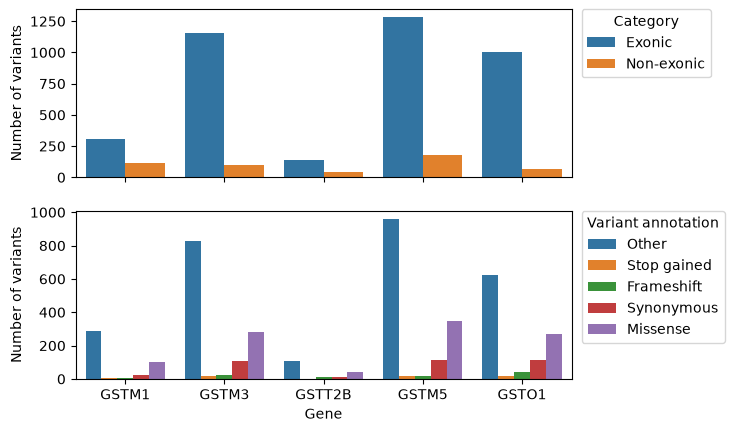

In [47]:
from matplotlib import pyplot as plt
import seaborn as sns

df_1b = (
    full_data
    .with_columns(
        pl.col("Source").replace(
            ["gnomAD Exomes", "gnomAD Exomes,gnomAD Genomes", "gnomAD Genomes"],
            ["Exonic", "Exonic", "Non-exonic"],
        )
    )
    .group_by(["Gene", "Source"]).len()
    .rename({"len": "Number of variants", "Source": "Category"})
    .to_pandas()
)

label_map = {
    "missense_variant": "Missense",
    "synonymous_variant": "Synonymous",
    "frameshift_variant": "Frameshift",
    "stop_gained": "Stop gained",
}
hue_order = ["Other", "Stop gained", "Frameshift", "Synonymous", "Missense"]

df_1c = (
    full_data
    .with_columns(
        pl.col("VEP Annotation")
        .replace_strict(label_map, default="Other")
        .alias("VEP Annotation")
    )
    .group_by(["Gene", "VEP Annotation"]).len()
    .rename({"len": "Number of variants", "VEP Annotation": "Variant annotation"})
    .to_pandas()
)

fig, ax = plt.subplots(2, 1, sharex=True)

sns.barplot(
    data=df_1b,
    x="Gene",
    y="Number of variants",
    hue="Category",
    ax=ax[0]
)

sns.barplot(
    data=df_1c,
    x="Gene",
    y="Number of variants",
    hue="Variant annotation",
    hue_order=hue_order,
    ax=ax[1]
)

ax[0].legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
)

ax[1].legend(
    title="Variant annotation",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
)

plt.show()

Generally, the exonic vs. non-exonic breakdown is similar to what it was for Gonzalez-Padilla, even though this isn't the same method. However, the "other" category makes up a much larger chunk of the variants in the second plot. Nonetheless, missense is the most common variant type of the ones plotted, which was also the case for Gonzalez-Padilla

### Fig 1D

Fig 1D only includes exonic variants, so this is not exactly aligned with Gonzalez-Padilla either, since I have not selected exonic regions as rigorously as her yet. However, the binning of variants according to MAF is the same as in her paper.

Percent of 1486 exonic variants in canonical transcripts whose MAF is:
  Singleton (<= 1e-5): 62.2%
  Very rare (1e-5 - 1e-3): 33.2%
  Rare (1e-3 - 1e-2): 2.2%
  Common (> 1e-2): 2.4%


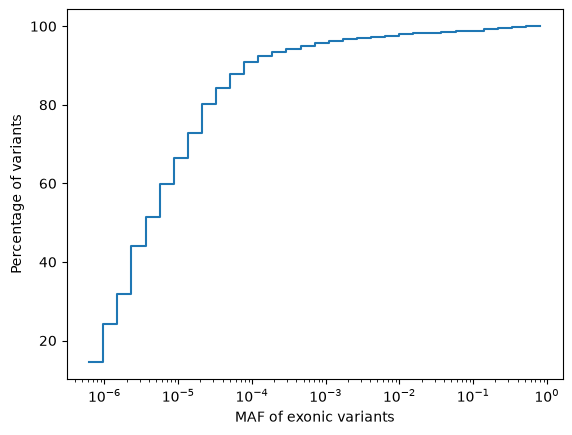

In [48]:
df_1d = (
    full_data
    .filter(
        ~pl.col("Source").is_in(["gnomAD Exomes"])
        & pl.col("CanonicalTranscript")
    )
    .select("Allele Frequency")
    .rename({"Allele Frequency": "MAF of exonic variants"})
)

def get_bin_pct(
    bounds: tuple[float, float],
    df: pl.DataFrame = df_1d,
    var: str = "MAF of exonic variants"
) -> float:
    lo, hi = bounds
    n = df.filter((pl.col(var) > lo) & (pl.col(var) <= hi)).height
    return 100 * n / df.height

bins = {
    "Singleton (<= 1e-5)": (0, 1e-5),
    "Very rare (1e-5 - 1e-3)": (1e-5, 1e-3),
    "Rare (1e-3 - 1e-2)": (1e-3, 1e-2),
    "Common (> 1e-2)": (1e-2, 1),
}

print(f"Percent of {len(df_1d)} exonic variants in canonical transcripts whose MAF is:")
for label, b in bins.items():
    print(f"  {label}: {get_bin_pct(b):.1f}%")

fig, ax = plt.subplots()

sns.histplot(
    data=df_1d.to_pandas(),
    x="MAF of exonic variants",
    cumulative=True,
    log_scale=True,
    element="step",
    fill=False,
    stat="percent",
    ax=ax
)

ax.set_ylabel("Percentage of variants")

plt.show()

## Key takeaways

Given that at this point I don't have the exonic variant selection methodology locked in, these findings should only be taken so far. Still, some general findings can be extracted:
- There are more exonic than non-exonic variants in all genes
- Unlike Gonzalez-Padilla's work on UGT, most of the variants do not fall into the classes $\{ \text{Stop gained, frameshift, synonymous, missense}\}$
- Of the classes mentioned above, missense appears the most frequently across genes, followed by synonymous. The same pattern was observed by Gonzalez-Padilla
- MAF of exonic variants follows a similar distribution as it did for UGT, with similar number of variants in each bin (the same bins as Gonzalez-Padilla used)